## Introduction

Ce Notebook presente le code pour récuperer les données nécessaires pour analyser les emissions dans la région l'île de France. Il est structuré de la manière suivante:

1) Comment est-ce qu'on a trouver les données? 
2) Qu'est-ce qu'on trouve sur les données? 

Il faut tourner le kernel avec les packages d'abord et après tourner 1) pour extraire les données de Airparif, ou aller directement vers la section 2) pour étudier les données. 

In [ ]:
import numpy as np
import pandas as pd
import requests
from functions_emissions import extract_values 
import s3fs
import geopandas as gpd
import matplotlib.pyplot as plt

## 1) Scraper les données des cartes de Airparif

1) On a besoin des concentrations de particules qui puissent nuire à la population. On utilise le NO2, PM2,5 et le O3. On note que la récupération de ses données n'est pas si directe comme on pourrait l'imaginer. En effet, le site the Airparif (qui est le site donnant les données sur la qualité de l'air de toute la région de l'île de France) ne donne que les valeurs des stations qui mesurent la qualité de l'air. Or, on a besoin de pouvoir une vision spatiale de toutes les communes et pas que de certaines stations. Alors, la récupération de ces données devient complexe. Néanmoins, Airparifs offre aussi des cartes intéractives qui donnent les niveaux de concentrations des particules. Donc, en utilisant ces cartes avec les données déjà modélisées sur toute l'Île de France, on pourrait réaliser notre étude. J'ai inspectionné le Slider donnant les cartes et j'ai trouvé d'oú je pouvais extraire les données depuis les geoservers de Airparifs. En inspectionant le slider j'ai pu retrouver la construction du lien des sites oú trouver les données. La fonction pour extraire les valeures sont dans le fichier .py.

2) Pour pouvoir utiliser les données on devra regrouper les données par communes de l'INSEE, donc on a besoin des coordonnées de centroïde de chaque commune. Pour cela on utilise la geo API de datagouv.fr, qui donne des coordonnées des communes.

L'idée est d'utiliser les coordonées des centroïdes des communes et de "scraper" la concentration des particules nuisant la qualité de l'air directement des données qui sont presentées sur la carte (qui modélisent directement la concentration des particules aux alentours des stations de mesure)

In [ ]:
# Données du Geoserver de Airparif 

url_base = "https://namek.airparif.fr/geoserver/Moyenne_annuelle/ows?service=WMS&version=1.3.0&request=GetFeatureInfo"
years = range(2007,2025)
particles = {"no2","o3","pm25"}


In [3]:
# Données des centroïdes des communes de l'île de france

url_communes = "https://geo.api.gouv.fr/communes"
departement_idf = ["75","77","78","91","92","93","94","95"]

data_centroides = []

for dep in departement_idf:
    parametres = {"codeDepartement": dep, "type": "commune-actuelle,arrondissement-municipal","fields": "nom,code,codeDepartement,centre", "format": "json"}
    r = requests.get(url_communes, params = parametres).json()
    data_centroides += r
    
ile_de_fr_commune = pd.DataFrame({
    "INSEE_Commune" : [com["code"] for com in data_centroides],
    "INSEE_Departement" : [com["codeDepartement"] for com in data_centroides],
    "Nom_Commune" : [com["nom"] for com in data_centroides],
    "Latitude" : [com["centre"]["coordinates"][1] for com in data_centroides],
    "Longitude" : [com["centre"]["coordinates"][0] for com in data_centroides]})

ile_de_fr_commune = ile_de_fr_commune.drop(index=0).reset_index(drop=True) # la premiere ligne est Paris en general, donc on l'enleve

In [ ]:
# Scraper les données de concentration pour chaque commune dans l'île-de-France (Cela a pris approx 100 min)
data_concentration = []

for communes in range(ile_de_fr_commune.shape[0]):
    for particule in particles:
        for year in years:
            concentration = extract_values(url_base, ile_de_fr_commune["Longitude"].loc[communes], ile_de_fr_commune["Latitude"].loc[communes], particule, year)
            dict_year_particle = {"Year": year, "Particle": particule, "Commune": ile_de_fr_commune["Nom_Commune"].loc[communes], "Code_INSEE": ile_de_fr_commune["INSEE_Commune"].loc[communes], "Departement": ile_de_fr_commune["INSEE_Departement"].loc[communes],"Concentration": concentration}
            data_concentration.append(dict_year_particle)


In [5]:
# Construction du Panel (Commune, année, Partibule_polluante) pour l'analyse
Data_Emissions = pd.DataFrame(data_concentration).pivot_table(index=["Commune", "Code_INSEE", "Departement", "Year"], columns= "Particle", values= "Concentration")

In [ ]:
# Stocker les données sur SSP Cloud

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
MY_BUCKET = "tomasmossel"

with fs.open(f"{MY_BUCKET}/diffusion/concentrations_idf.parquet", "wb") as f:
    Data_Emissions.to_parquet(f)


## 2) Étude et Description des Données

Maintenant que on a le panel de données avec toutes les particules par commune par année, on peut commencer à faire l'analyse des statistiques des données. On structure cette section de la façon suivante:

0) Presentation des données extraites des cartes de Airparifs
1) Tout d'abord, on regarde de manière générale la distribution des valeurs 
2) Analyse geographique: Où trouvons-nous les zones les plus polluées?
3) Analyse Temporelle: Voit-on des dynamiques? Peut-on observer des shocks importants?

In [3]:
# Ouvrir le parquet directement de SSpCloud

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
MY_BUCKET = "tomasmossel"

with fs.open(f"{MY_BUCKET}/diffusion/concentrations_idf.parquet", "rb") as f:
    Data_Emissions = pd.read_parquet(f)

### 2.1) Description des données

Nos données pour les emissions/polluants principaux de l'Île-de-France couvrent des effets differentes qui vont impacter la qualité de l'air et donc la santé de la population. Pour le choix des gaz et particules à inclure dans notre étude, on se base sur les articles déjà existants. On a tout d'abord la pollution provenant des véhicules à énergie fossile, majoritairement représentée par le Dyoxide d'Azote ($\mathrm{NO_2}$). De plus, les particules fines ($\mathrm{PM_{2.5}}$) qui ont pour source la combustion du bois, le traffic et l'industrie. C'est important de prendre en compte ces particules puisqu'elles sont fortement liées à la mortalité. Finalement, l'ozone $\mathrm{O_3}$ est aussi souvent pris en compte lors des études sur la qualité de l'air puisque ce gaz affecte la respiration et à des effet négatifs lors des pics de concentration. 

Airparif donne les cartes de series temporelles de ces polluants de formes differentes: pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$ on a les concentrations moyennes annuelles de l'année 2007 à l'année 2024, pour les particules fines $\mathrm{PM_{2.5}}$ on a le nombre de jours par année oú les concentrations dépassent les 120 microgrammes par mètre cube pendant plus de 8h. 

#### 2.1.1) Problèmes avec les données

Tout d'abord, on s'interesse à la structure des données poour voir si il y a eu des problèmes dans l'extraction des données. Ici, on peut voir qu'il y a un problème avec les données de certaines communes. Donc, on exlore quelle est la source de ce problème en regardant quelles sont les communes donnant ces valeures abérrantes. On peut voir que le problème vient que de la commune de Saint-Pathus, et que en l'enlevant de notre échantillon, on obtient des valeurs beaucoup plus raisonables. 

Les données de cette communes sont l'équivalent à des données NA puisque elles n'ont aucune validité. Pour ne pas corrompre notre analyse, on excluira cette commune. Cela est raisonable puisque c'est une petitte commune frontalière de l'île de france, et donc, l'exclusion n'aura pas de grandes conséquences sur nos résultats.

In [5]:
Data_Emissions.describe()

/opt/python/lib/python3.13/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/opt/python/lib/python3.13/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


Particle,no2,o3,pm25
count,23129.000000,2.312900e+04,2.312800e+04
mean,9.059044,inf,inf
std,263.460748,inf,inf
min,-9999.000000,-9.999000e+03,-9.999000e+03
25%,9.666734,7.769344e+00,8.835938e+00
50%,14.645324,1.168689e+01,1.130522e+01
75%,20.705441,1.724444e+01,1.402599e+01
max,69.558527,1.234500e+308,1.234500e+308


In [6]:
Data_Emissions[Data_Emissions["o3"] >= 100]

Particle                                     no2             o3           pm25
Commune      Code_INSEE Departement Year                                      
Saint-Pathus 77430      77          2007 -9999.0  1.234500e+308  -9.999000e+03
                                    2008 -9999.0  1.234500e+308  -9.999000e+03
                                    2009 -9999.0  1.234500e+308  -9.999000e+03
                                    2010 -9999.0  1.234500e+308  -9.999000e+03
                                    2011 -9999.0  1.234500e+308  -9.999000e+03
                                    2012 -9999.0  1.234500e+308  -9.999000e+03
                                    2013 -9999.0  1.234500e+308  -9.999000e+03
                                    2014 -9999.0  1.234500e+308  -9.999000e+03
                                    2018 -9999.0  1.234500e+308  1.234500e+308
                                    2019 -9999.0   1.234500e+38   1.234500e+38
                                    2020 -9999.0  1.234500e+308   1.234500e+38
                                    2021 -9999.0  1.234500e+308   1.234500e+38

In [7]:
Data_Emissions = Data_Emissions.drop("Saint-Pathus", level="Commune")
Data_Emissions.describe()

Particle,no2,o3,pm25
count,23112.000000,23112.000000,23112.000000
mean,15.987309,12.591292,11.770842
std,8.478551,6.656286,3.476377
min,2.177196,0.000000,6.062500
25%,9.673809,7.769270,8.835938
50%,14.652687,11.684671,11.306413
75%,20.713225,17.238471,14.021851
max,69.558527,39.922986,31.783500


#### Description géographique des données

Maintenant qu'on a une meilleur idée de la forme de nos données, on peut aller plus loin sur l'analyse.
On va commencer par une étude departementale pour voir si on peut déjà expliquer les differences en concentrations.

In [ ]:
url = ("https://geo.api.gouv.fr/communes?codeRegion=11&type=commune-actuelle,arrondissement-municipal&format=geojson&geometry=contour&fields=code,nom")

communes_geo_distrib = gpd.read_file(url)
communes = communes_geo_distrib[communes_geo_distrib["code"] != "75056"]  # On enlève la commune de Paris (on prend les arrondissement)


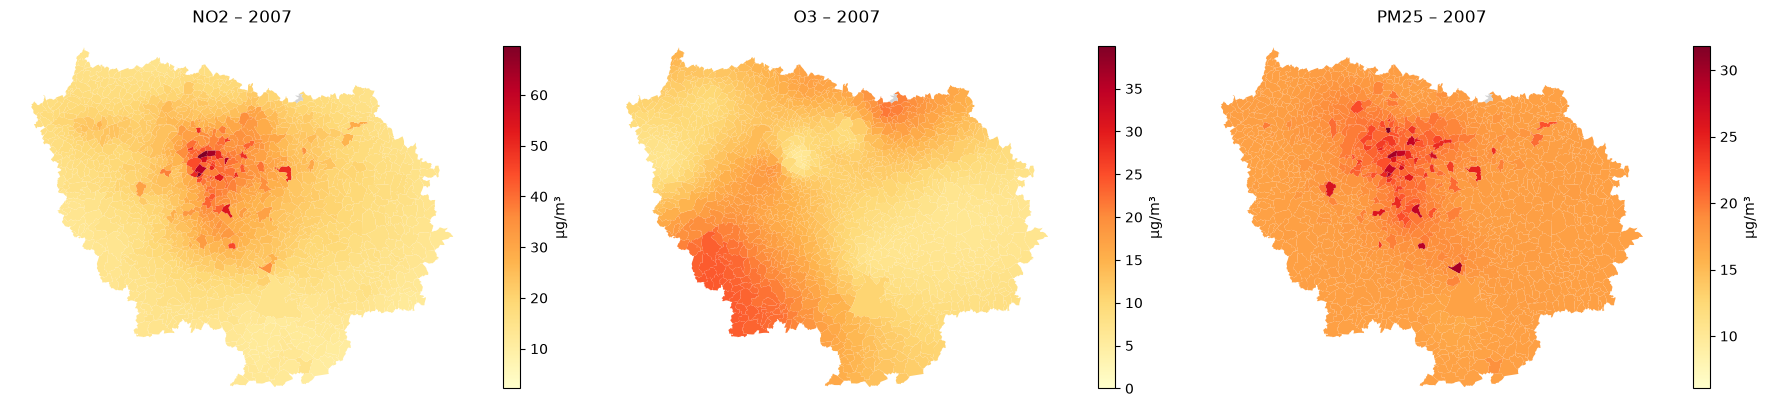

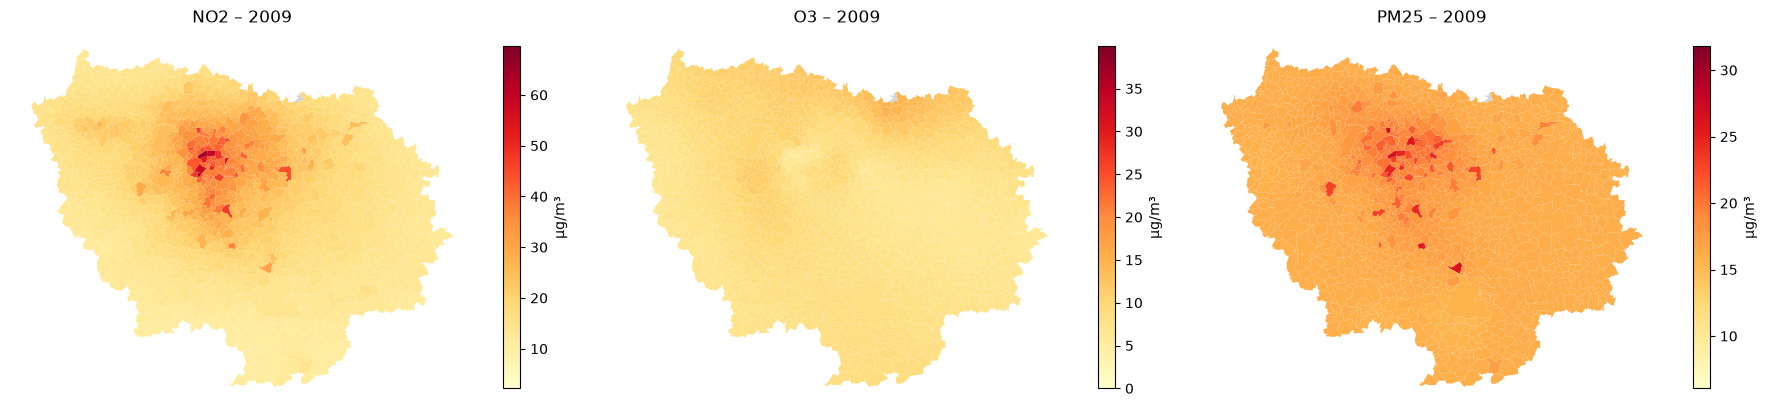

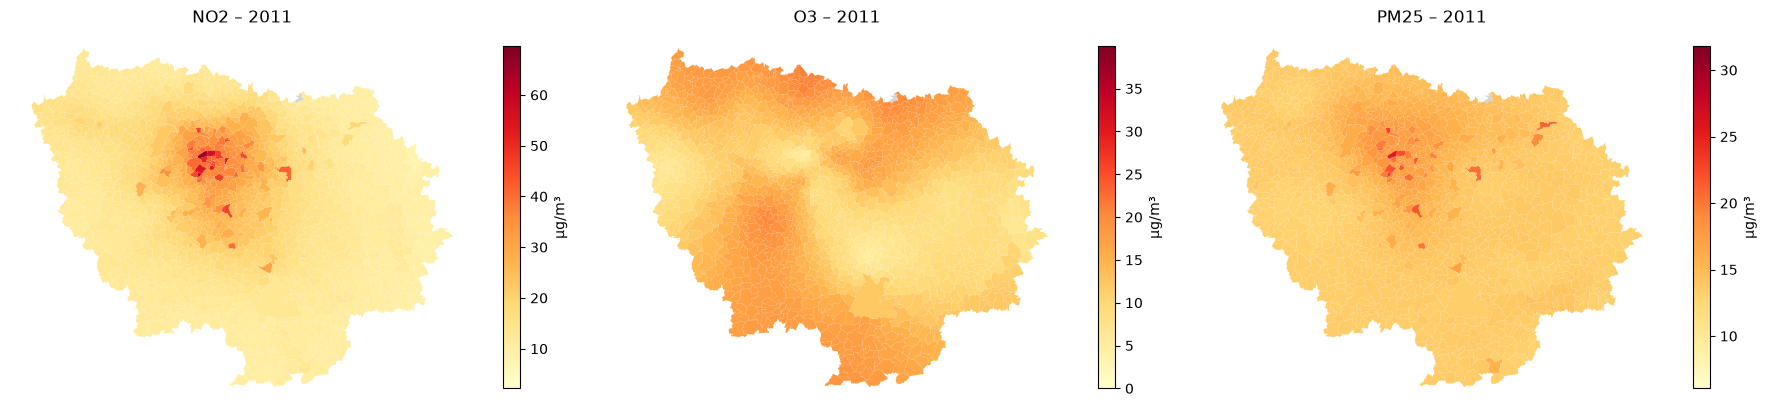

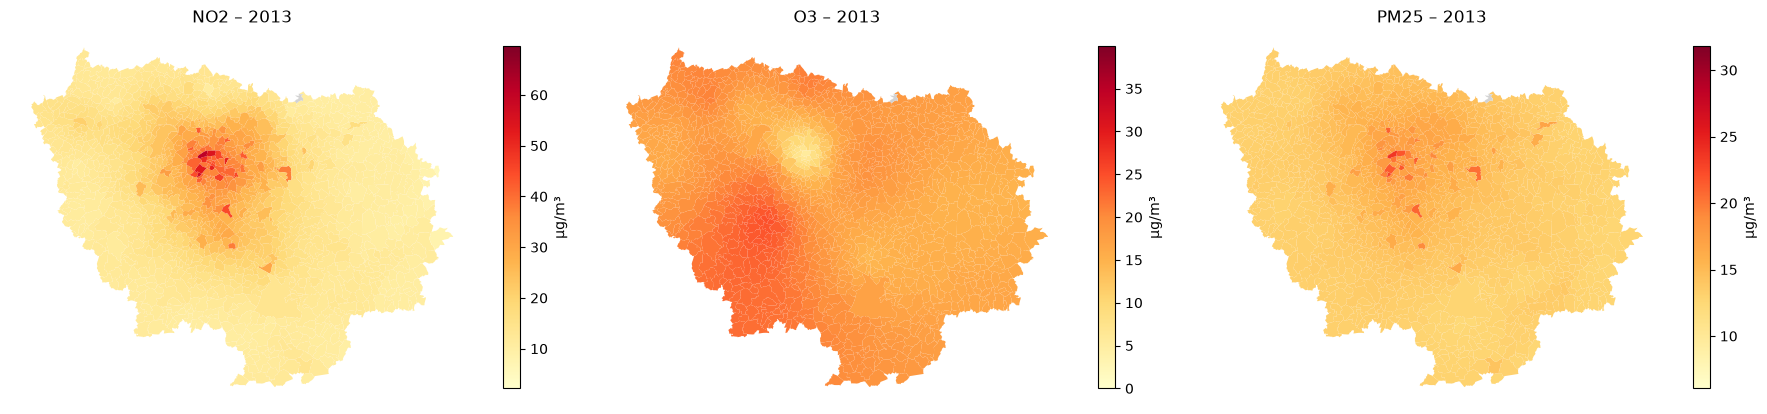

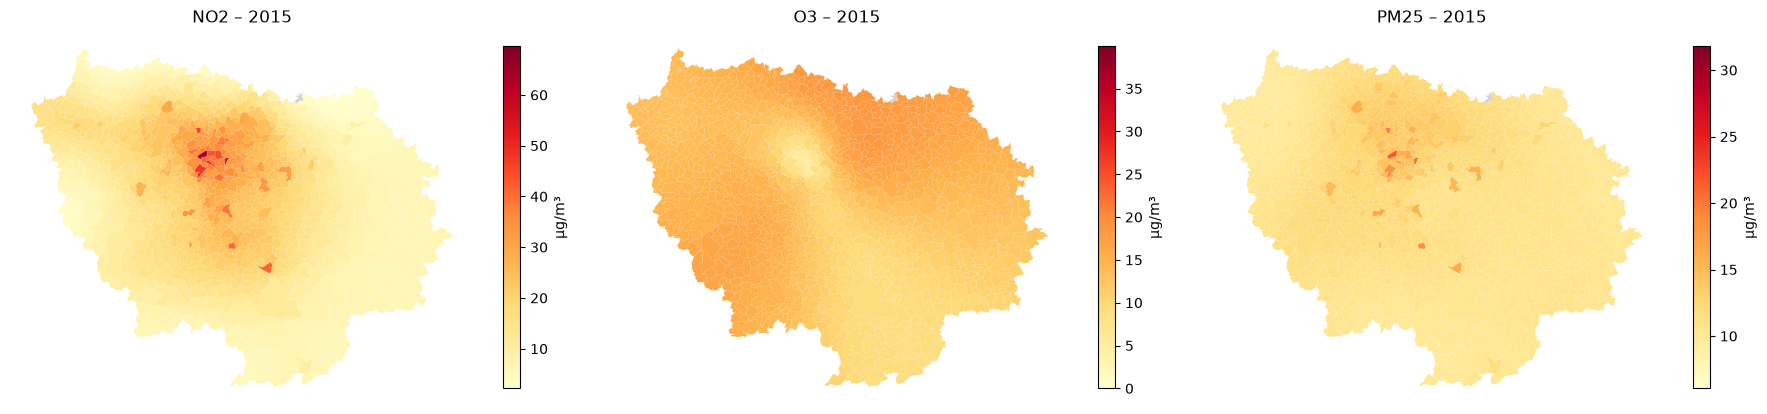

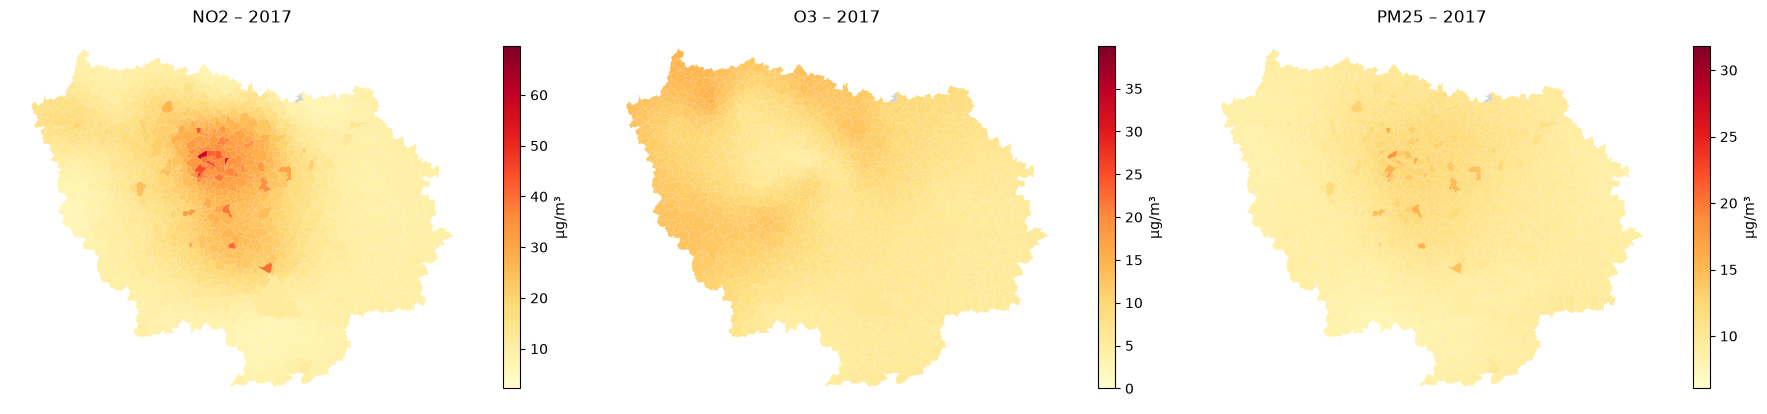

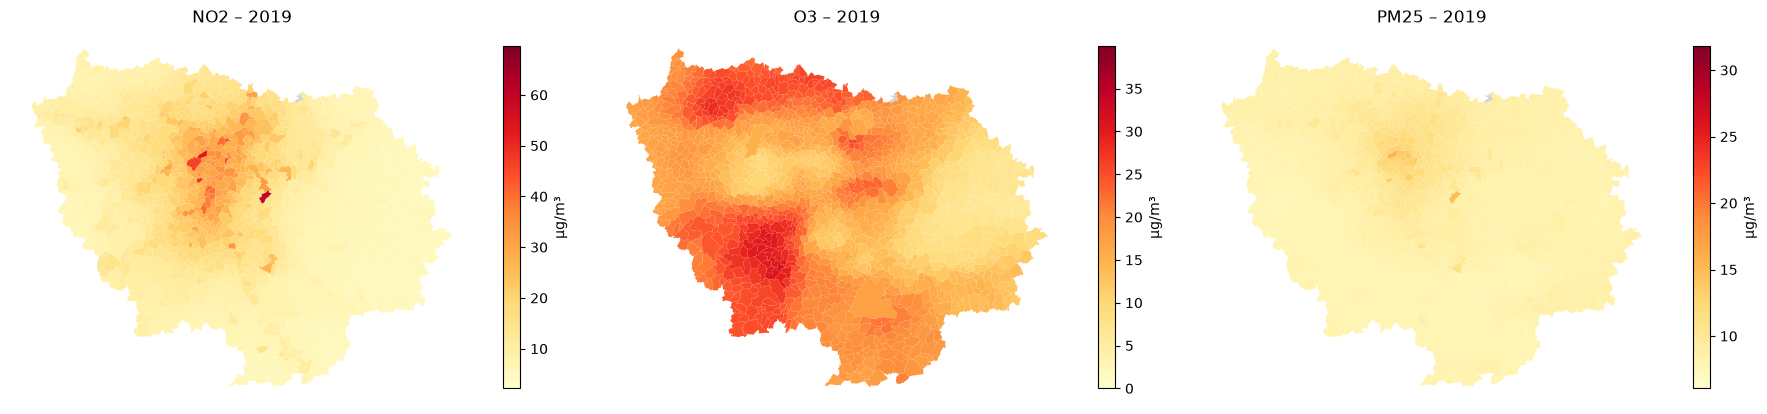

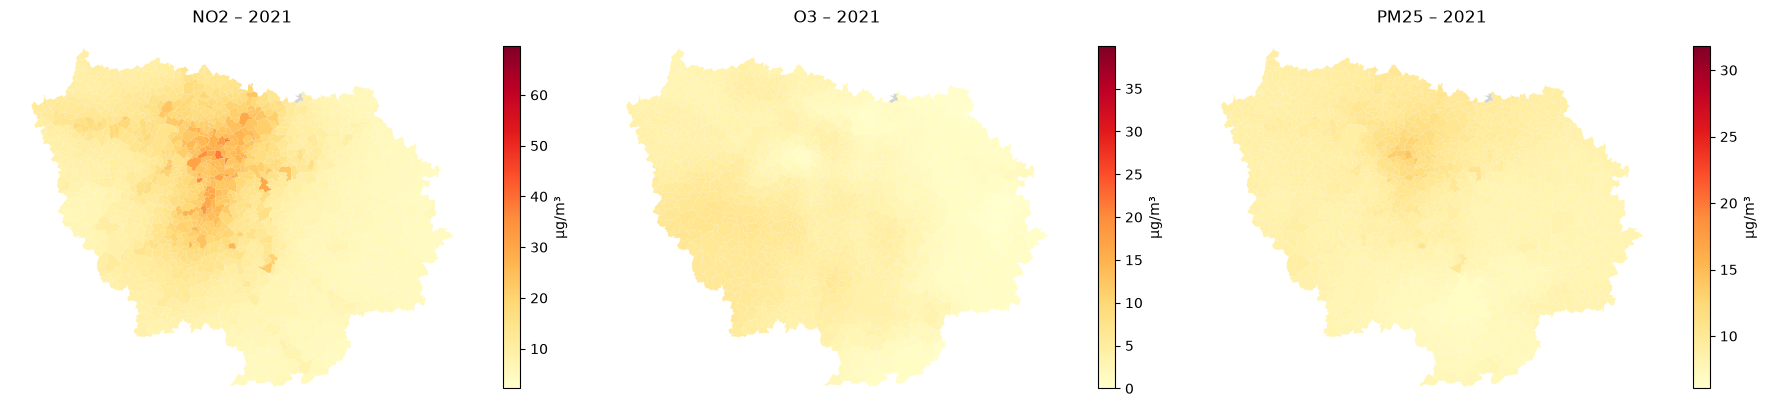

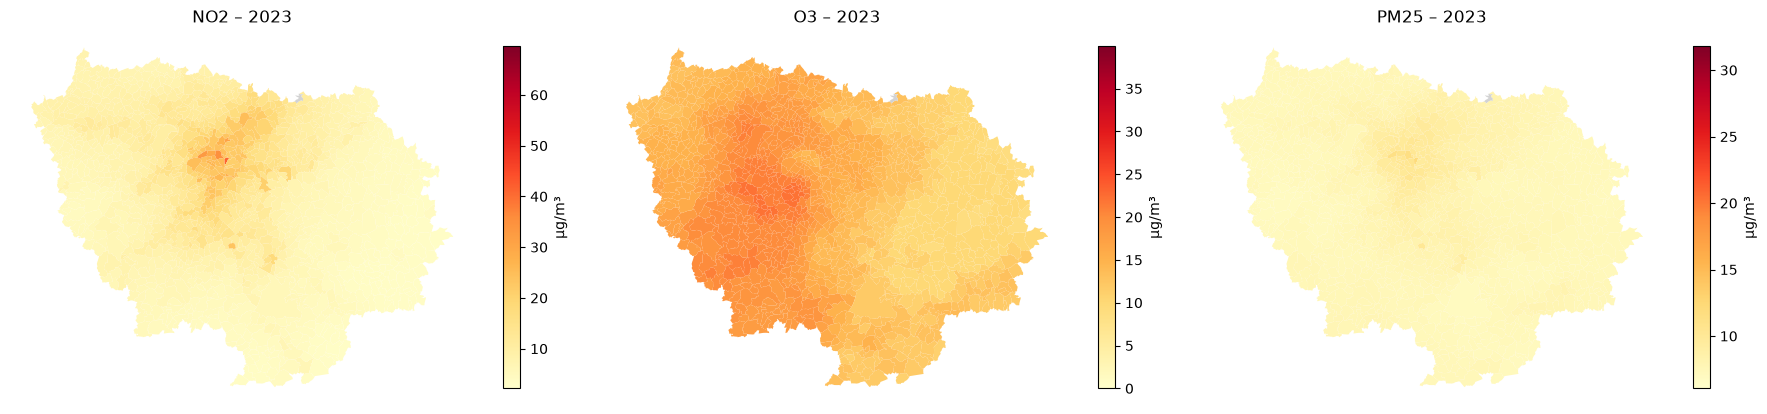

In [17]:
avg = Data_Emissions.groupby(level=["Code_INSEE","Year"]).mean().reset_index(level="Year")
avg.index = avg.index.astype(str)   
avg.columns.name = None

particles = ["no2", "o3", "pm25"]
lims = {p: (avg[p].min(), avg[p].max()) for p in particles}

for year in range(2007,2024, 2):

    year_data = avg[avg["Year"] == year].drop(columns="Year")
    gdf = communes.merge(year_data, left_on="code", right_index=True, how="left")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, p in zip(axes, ["no2", "o3", "pm25"]):
        vmin,vmax = lims[p]
        gdf.plot(column=p, cmap="YlOrRd", ax=ax,vmin=vmin, vmax=vmax, legend=True,
                legend_kwds={"label": "µg/m³", "shrink": 0.6},
                missing_kwds={"color": "lightgrey"})
        ax.set_title(f"{p.upper()} – {year}")
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

À première vue, on observe que les communes présentant les concentrations les plus élevées sont les communes de la zone métropolitaine parisienne pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$, tandis que pour le $\mathrm{O_3}$ c'est le contraire. De plus, on voit qu'en général, les concentrations diminuent au cours du temps pour chacun des polluants avec une baisse plus régulière pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$ que pour le $\mathrm{O_3}$ qui n'a pas une évolution monotone. Pour pouvoir interpréter cela, il faut aller regarder la composition de chacune des particules et des gaz, et leurs origines. 

En effet, le $\mathrm{NO_2}$ est majoritairement produit par les véhicules utilisant des énergies fossiles, ce qui est en ligne avec le fait que les zones parisiennes soient les plus exposées à ces gaz (aussi, on peut voir une concentration plus forte vers les grands axes routiers (periférique, grandes routes)). Par ailleurs, avec les régulations européennes, l'augmentation des véhicules éléctriques et l'implantation des zones à faibles émissions, les concentrations ont diminué substantiellement. De plus, on qu'il y a des communes éloignées du centre de Paris qui ont des niveaux élevés de $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$. Cela pourrait être du à leur proximité aux autoroutes oú axes routiers.

De même, les particules $\mathrm{PM_{2.5}}$, on observe une diminuiton importante au cours du temps avec des faibles concentrations vers la fin de notre échantillon. 

Concernant l'ozone $\mathrm{O_3}$, on peut voir que les zones plus affectées ne sont pas les mêmes que pour les deux autres polluants. Ici, la zone de la ville de Paris semble être moins affectée que le sud-ouest de l'île de france. Cela est du au fait que le $\mathrm{O_3}$ rentre en réaction avec le monoxyde d'azote et donne du $\mathrm{NO_2}$ et de $\mathrm{O_2}$. Cela

In [15]:
Data_Emissions_Dep = Data_Emissions.groupby(level=["Departement", "Commune"]).mean()
Data_Emissions_Dep.sort_values(["no2"], ascending=[False]).head(20)

Particle                                    no2         o3       pm25
Departement Commune                                                  
75          Paris 17e Arrondissement  54.291252   8.007388  19.665722
93          Bagnolet                  48.917384  10.800366  17.702122
92          Vanves                    45.658135  11.176984  18.045124
75          Paris 18e Arrondissement  44.778368   7.993972  17.376227
            Paris 19e Arrondissement  42.461683   9.298421  16.395474
            Paris 15e Arrondissement  41.980013   9.817961  17.105485
93          Le Bourget                40.257379  11.570482  16.340862
75          Paris 8e Arrondissement   40.060885   8.264198  16.066167
            Paris 5e Arrondissement   39.097340   9.807988  16.538740
94          Ivry-sur-Seine            38.882709  11.300061  16.118008
75          Paris 4e Arrondissement   38.865631   9.451209  15.678113
            Paris 1er Arrondissement  38.373920   8.923195  15.487008
95          Saint-Gratien             37.882755  12.048539  18.136278
92          Châtillon                 37.391320  12.185790  15.565728
75          Paris 3e Arrondissement   36.762879   9.149517  15.087750
94          Joinville-le-Pont         36.719897  11.694273  15.044209
91          Vigneux-sur-Seine         36.554014  11.871451  16.732179
            Villabé                   36.388539  11.844513  17.026950
93          La Courneuve              36.121331  11.093727  16.466403
75          Paris 16e Arrondissement  36.050111   9.184009  14.504686

En regardant les communes qui en moyenne présentent des concentrations de $\mathrm{NO_2}$ plus élevées, on peut voir que les communes paarisiennes, près du périphériques, ou près d'es axes routiers sont les plus affectées. 

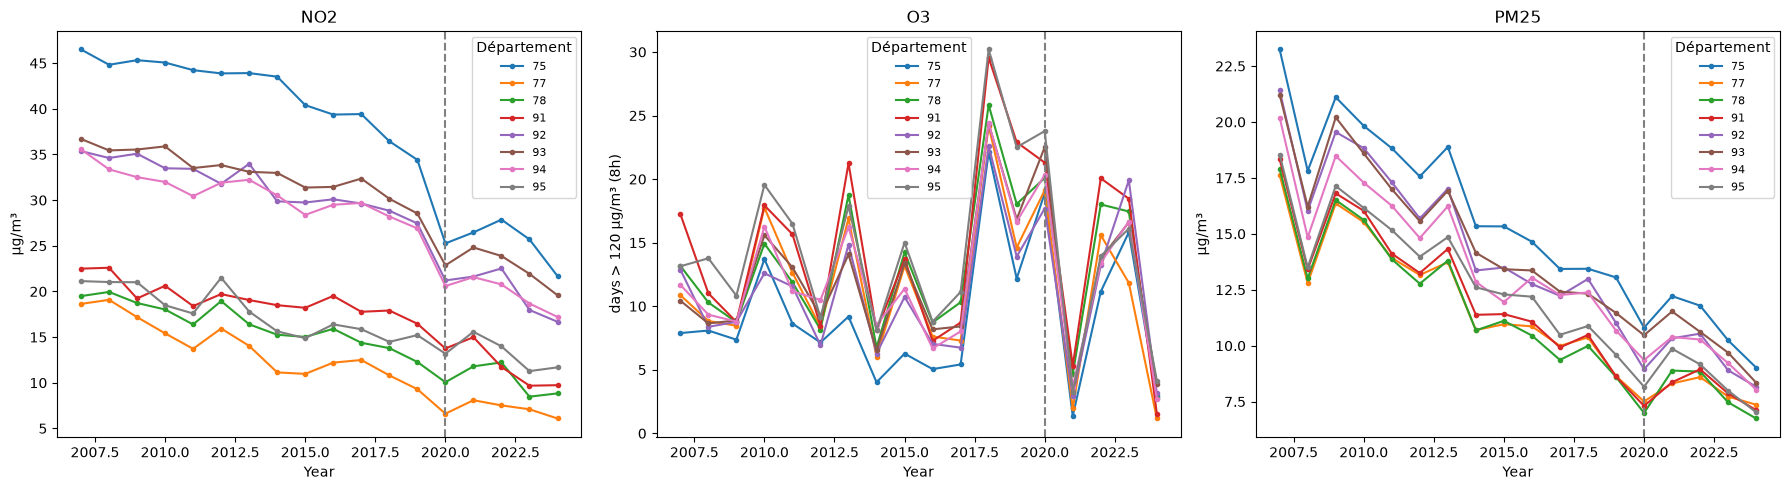

In [24]:
# Séries Temporelles des concentrations par département

Data_Emissions_temp = Data_Emissions.groupby(level = ["Departement", "Year"]).mean()

units = {"no2": "µg/m³", "o3": "days > 120 µg/m³ (8h)", "pm25": "µg/m³"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, p in zip(axes, ["no2", "o3", "pm25"]):
    Data_Emissions_temp[p].unstack("Departement").plot(ax=ax, marker="o", ms=3)
    ax.axvline(2020, color= "grey", linestyle="--")
    ax.set_title(p.upper())
    ax.set_xlabel("Year")
    ax.set_ylabel(units[p])
    ax.legend(title="Département", fontsize=8)
plt.tight_layout()
plt.show()



C'est interessant de regarder les séries tempoerlles pour observer les tendances de chacun des polluants. En particulier, on peut observer que le COVID 19 a eu un impact substantiel sur les concentrations de $\mathrm{NO_3}$ et $\mathrm{PM_{2.5}}$. Cela est raisonable puisque le confinement restraint les déplacements et donc réduit les emissions de ces gaz. De plus, on peut voir que l'effet est plus important dans Paris, ce qui est normal puisque c'est le centre économique de la région et donc acceuille la majorité des déplacements. 

Pour l'ozone, on observe une évolution très différente. En effet, cela est du par la forte correlation entre la concentration de $\mathrm{O_3}$ et la chaleur. On peut observer des pics de jours de haute concentration de $\mathrm{O_3}$ en 2018, 2019, 2020, et 2022, qui sont dans la liste des années avec les été les plus chaloureux depuis 1950. Donc, cette variation est expliquée par ce phénomène. Pour notre projet, ce sera important de tenir en compte ce lien puisque la mortalité sera surement correlée avec ces années de hautes chaleures.